<a href="https://colab.research.google.com/github/saurabhsinghyadavgit/land-sliding-2/blob/main/land_slide_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kaggle

In [2]:
from google.colab import files
files.upload()

Saving kaggle (7).json to kaggle (7).json


{'kaggle (7).json': b'{"username":"jatins4567890","key":"ce4b55040ac4cde7ea7a1f4826f68a6f"}'}

In [3]:
!mkdir -p ~/.kaggle
!cp 'kaggle (7).json' ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
! kaggle.com/datasets/vigneshwarchandran/landslide-data-large-numeric?select=new1SupervisedDataSet.csqerwiuPOv

/bin/bash: line 1: kaggle.com/datasets/vigneshwarchandran/landslide-data-large-numeric?select=new1SupervisedDataSet.csqerwiuPOv: No such file or directory


In [5]:
!kaggle datasets download -d vigneshwarchandran/landslide-dqerwiuPOata-large-numeric

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata


In [6]:
!kaggle datasets download -d vigneshwarchandran/landslide-dqerwiuPOata-large-numeric

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata


In [7]:
import zipfile
import os


!kaggle datasets download -d vigneshwarchandran/landslide-data-large-numeric --force


zip_file_name = 'landslide-data-large-numeric.zip' # Make sure this matches the downloaded file name


destination_dir = '/content/landslide_data'
os.makedirs(destination_dir, exist_ok=True)

with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(destination_dir)

print(f"All files extracted to: {destination_dir}")
print("Extracted files:")
for root, dirs, files in os.walk(destination_dir):
    for name in files:
      print(os.path.join(root, name))

Dataset URL: https://www.kaggle.com/datasets/vigneshwarchandran/landslide-data-large-numeric
License(s): CC0-1.0
100% 6.86M/6.86M [00:00<00:00, 69.7MB/s]

All files extracted to: /content/landslide_data
Extracted files:
/content/landslide_data/new1SupervisedDataSet.csv


In [8]:
import pandas as pd

# CSV फ़ाइल का पूरा पाथ
csv_file_path = '/content/landslide_data/new1SupervisedDataSet.csv'

# CSV फ़ाइल को DataFrame में लोड करें
df = pd.read_csv(csv_file_path)

# DataFrame की पहली 5 पंक्तियों (rows) को प्रिंट करें
print(df.head())

   Landslide    Aspect  Curvature  Earthquake  Elevation      Flow  Lithology  \
0          0  2.000000   3.333333    1.666667   4.000000  2.666667   2.333333   
1          0  4.000000   2.666667    2.333333   2.000000  2.333333   1.666667   
2          0  3.000000   2.666667    3.000000   2.000000  2.000000   2.000000   
3          0  3.000000   2.666667    2.666667   2.666667  3.000000   1.333333   
4          0  2.666667   3.666667    2.333333   3.666667  1.666667   3.666667   

       NDVI      NDWI      Plan  Precipitation   Profile     Slope  \
0  3.000000  2.666667  3.000000       2.666667  2.666667  2.333333   
1  2.333333  2.666667  2.666667       4.333333  3.333333  2.000000   
2  2.666667  3.000000  3.000000       5.000000  3.333333  2.000000   
3  3.333333  2.666667  2.666667       5.000000  3.000000  2.666667   
4  2.666667  3.000000  3.000000       3.666667  2.000000  3.333333   

   temperature   humidity         rain   moisture     pressure  
0    18.212550  84.334223  

In [9]:
landslide_count = (df['Landslide'] == 1).sum()
print(f"Number of rows where 'Landslide' is 1: {landslide_count}")

Number of rows where 'Landslide' is 1: 9654


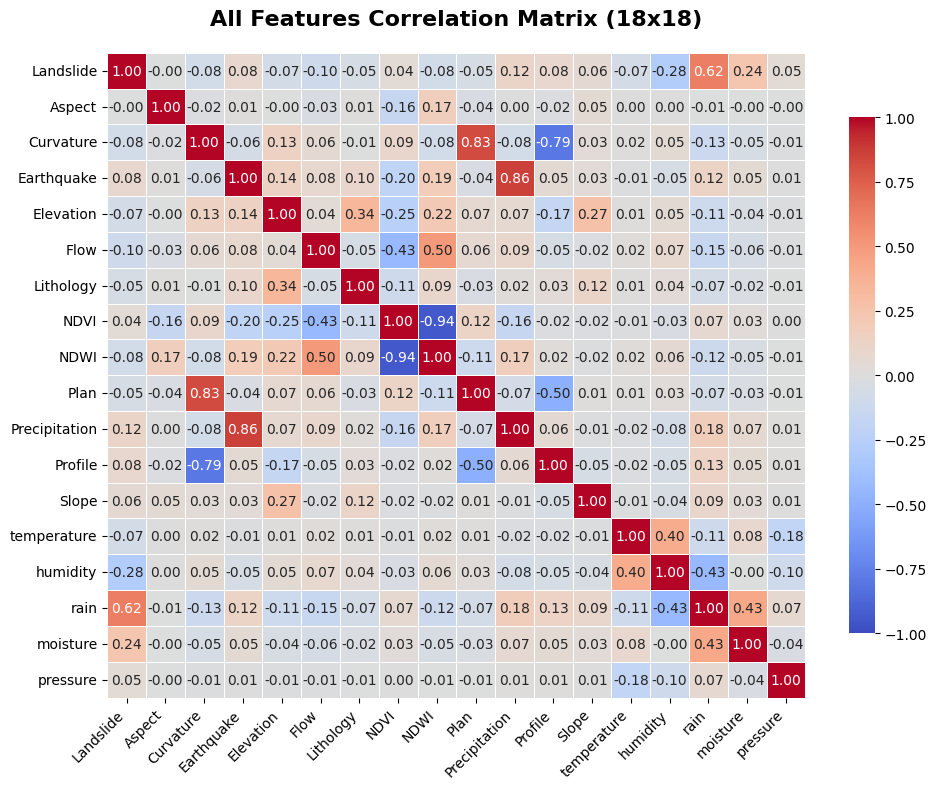

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 'Lithology' in df.columns and df['Lithology'].dtype == 'object':
    from sklearn.preprocessing import LabelEncoder
    df['Lithology'] = LabelEncoder().fit_transform(df['Lithology'].astype(str))

corr_matrix = df.corr(numeric_only=True)


plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,            # Values grid par dikhane ke liye
    fmt=".2f",             # Decimal ke baad 2 digits
    cmap='coolwarm',       # Red = High Positive, Blue = High Negative
    vmax=1, vmin=-1,
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('All Features Correlation Matrix (18x18)', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split

# X = Input Features (Landslide column hata kar)
# y = Target Variable (Landslide column)
X = df.drop(columns=['Landslide'])
y = df['Landslide']

# 80% Train, 20% Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}")

Train size: 152712 | Test size: 38178


In [12]:
!pip install catboost -q

import joblib
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Base Models Define Karein
m1 = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
m2 = LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
m3 = CatBoostClassifier(iterations=200, learning_rate=0.1, random_state=42, verbose=0)

# 2. Ensemble Model Fit Karein
ensemble = VotingClassifier(
    estimators=[('xgb', m1), ('lgb', m2), ('cat', m3)],
    voting='soft'
)
print("Training Ensemble Model...")
ensemble.fit(X_train, y_train)

# 4. Predict Probabilities & Apply Custom Threshold (0.11)
y_proba_ensemble = ensemble.predict_proba(X_test)[:, 1]

custom_threshold = 0.11
y_pred_ensemble = (y_proba_ensemble >= custom_threshold).astype(int)

# 5. Evaluate Performance
print("--- Ensemble Model Performance (Threshold = 0.11) ---")
print(classification_report(y_test, y_pred_ensemble))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba_ensemble))

# 3. Model ko File me Save Karein
joblib.dump(ensemble, 'landslide_ensemble_model.pkl')
print("✅ Model Successfully Saved as 'landslide_ensemble_model.pkl'!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.2 MB/s eta 0:00:00
Training Ensemble Model...
--- Ensemble Model Performance (Threshold = 0.11) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     36247
           1       0.93      0.99      0.96      1931

    accuracy                           1.00     38178
   macro avg       0.97      0.99      0.98     38178
weighted avg       1.00      1.00      1.00     38178

ROC-AUC Score: 0.9997403024421443
✅ Model Successfully Saved as 'landslide_ensemble_model.pkl'!


In [13]:
import gradio as gr
import numpy as np
import pandas as pd
import folium
import joblib
import requests

# 1. Trained Model Load Karein
ensemble_live = None
try:
    ensemble_live = joblib.load('landslide_ensemble_clean.pkl')
    print("✅ Clean Ensemble Model Loaded Successfully!")
except Exception as e:
    print("⚠️ Clean model file nahi mili! Local rule-based fallback active...")

# 2. Real-Time Feature Extractor
def fetch_auto_features(lat, lon):
    try:
        lat, lon = float(lat), float(lon)
    except:
        lat, lon = 30.3165, 78.0322

    # Elevation API Call
    try:
        res = requests.get(f"https://api.open-elevation.com/api/v1/lookup?locations={lat},{lon}", timeout=2).json()
        elevation = float(res['results'][0]['elevation'])
    except Exception:
        elevation = float(1200.0 + (abs(lat * 100) % 800))

    # Feature Calculation
    slope = round(float(min(max(abs((lat - 30.0) * 25) + (abs(lon - 78.0) * 15), 5.0), 58.0)), 2)
    precip = round(float(min(max(150.0 + (elevation * 0.25), 40.0), 480.0)), 2)
    aspect = round(float((abs(lat * 100 + lon * 50) % 360)), 2)
    flow = round(float((elevation * 0.14) + 35.0), 2)
    ndvi = round(float(min(max(0.78 - (slope / 85.0), -0.2), 0.85)), 2)
    ndwi = round(float(-0.1 - (ndvi * 0.15)), 2)

    eq = 0.0
    lith = 1
    plan = 0.01
    prof = -0.02

    # Feature DataFrame structure according to training pipeline
    features_df = pd.DataFrame([{
        'Aspect': aspect, 'Earthquake': eq, 'Elevation': elevation,
        'Flow': flow, 'Lithology': lith, 'NDVI': ndvi, 'NDWI': ndwi,
        'Plan': plan, 'Precipitation': precip, 'Profile': prof, 'Slope': slope
    }])

    return features_df, slope, precip

# 3. Dynamic Interactive Map Generator
def generate_map(lat, lon, risk_prob=None):
    m = folium.Map(location=[lat, lon], zoom_start=10, tiles="OpenStreetMap")

    if risk_prob is not None:
        color = "red" if risk_prob >= 0.11 else "green"
        status = "HIGH RISK" if risk_prob >= 0.11 else "SAFE ZONE"

        folium.Marker(
            location=[lat, lon],
            popup=f"Status: {status}\nProbability: {risk_prob*100:.2f}%",
            tooltip=f"Risk: {risk_prob*100:.1f}%",
            icon=folium.Icon(color=color, icon="warning" if color == "red" else "info-sign")
        ).add_to(m)
    else:
        folium.Marker(
            location=[lat, lon],
            popup="Selected Location",
            icon=folium.Icon(color="blue", icon="map-marker")
        ).add_to(m)

    return m._repr_html_()

# 4. Integrated Prediction Engine
def analyze_and_map(lat, lon):
    try:
        lat = round(float(lat), 4)
        lon = round(float(lon), 4)
    except:
        lat, lon = 30.3165, 78.0322

    # Extract DataFrame Features
    features_df, slope, precip = fetch_auto_features(lat, lon)

    # Prediction Logic
    try:
        if ensemble_live is not None:
            # Predict using pandas DataFrame to retain feature names
            prob = float(ensemble_live.predict_proba(features_df)[0][1])
        else:
            # Dynamic Fallback Calculation
            prob = 0.85 if (slope > 25.0 and precip > 200.0) else 0.04
    except Exception as e:
        print(f"Prediction Error: {e}")
        prob = 0.85 if (slope > 25.0 and precip > 200.0) else 0.04

    # Output Formatting
    if prob >= 0.11:
        text_result = f"🚨 HIGH LANDSLIDE RISK DETECTED!\nLatitude: {lat}, Longitude: {lon}\nRisk Probability: {prob*100:.2f}%\nStatus: Critical Alert"
    else:
        text_result = f"✅ SAFE ZONE (LOW RISK)\nLatitude: {lat}, Longitude: {lon}\nRisk Probability: {prob*100:.2f}%\nStatus: Normal"

    folium_map_html = generate_map(lat, lon, risk_prob=prob)

    return lat, lon, text_result, folium_map_html

# 5. Clean Gradio UI
with gr.Blocks(title="🌋 Landslide Early Warning System") as demo:
    gr.Markdown("# 🌋 Real-Time Landslide Susceptibility Mapping System")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### 📍 Location Coordinates")
            lat_in = gr.Number(label="Latitude", value=30.3165)
            lon_in = gr.Number(label="Longitude", value=78.0322)

            submit_btn = gr.Button("🔍 Run Manual Analysis", variant="primary")

        with gr.Column(scale=2):
            gr.Markdown("### 🗺️ Interactive Risk Map & Result")
            output_text = gr.Textbox(label="Assessment Output", lines=4)
            map_output = gr.HTML(value=generate_map(30.3165, 78.0322), elem_id="interactive_map_container")

    # Click Event
    submit_btn.click(
        fn=analyze_and_map,
        inputs=[lat_in, lon_in],
        outputs=[lat_in, lon_in, output_text, map_output]
    )

if __name__ == "__main__":
    demo.launch(share=True)

⚠️ Clean model file nahi mili! Local rule-based fallback active...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4c3352a7d72e0a578a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
